In [3]:
# 导入wine数据集
# 导入sklearn模块
from sklearn.datasets import load_wine
import numpy as np
# 加载wine数据集
wine = load_wine()
# "data"是特征数据集
X = wine.data
# "target"是目标变量数据(酒的类别标签)
y = wine.target
# 查看特征数据的维度
print('wine数据集的维度为：', X.shape)
# 查看酒的类别
print('wine数据集的类别标签为：', np.unique(y))


wine数据集的维度为： (178, 13)
wine数据集的类别标签为： [0 1 2]


In [4]:
# 导入数据集拆分工具
from sklearn.model_selection import train_test_split
# 将数据集拆分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=8)
# 输出训练数据集中特征向量的形态
print('训练集数据维度：', X_train.shape)
# 输出训练数据集中目标标签的形态
print('训练集标签维度：', y_train.shape)
# 输出测试数据集中特征向量的形态
print('测试集数据维度：', X_test.shape)
# 输出测试数据集中特征向量的形态
print('测试集标签维度：', y_test.shape)


训练集数据维度： (133, 13)
训练集标签维度： (133,)
测试集数据维度： (45, 13)
测试集标签维度： (45,)


In [5]:
# 导入StandardScaler
from sklearn.preprocessing import StandardScaler
# 对训练集进行拟合
scaler = StandardScaler().fit(X_train)
# 对训练集数据进行转换
X_train_scaled = scaler.transform(X_train)
# 对测试集数据进行转换
X_test_scaled = scaler.transform(X_test)
print('标准化前训练集数据的最小值和最大值：{0:1.2f}, {1:1.2f}'.format(X_train.min(), X_train.max()))
print('标准化后训练集数据的最小值和最大值：{0:1.2f}, {1:1.2f}'.format(X_train_scaled.min(), X_train_scaled.max()))
print('标准化前测试集数据的最小值和最大值：{0:1.2f}, {1:1.2f}'.format(X_test.min(), X_test.max()))
print('标准化后测试集数据的最小值和最大值：{0:1.2f}, {1:1.2f}'.format(X_test_scaled.min(), X_test_scaled.max()))


标准化前训练集数据的最小值和最大值：0.13, 1680.00
标准化后训练集数据的最小值和最大值：-3.93, 4.46
标准化前测试集数据的最小值和最大值：0.14, 1510.00
标准化后测试集数据的最小值和最大值：-2.60, 3.68


In [6]:
# 导入PCA
from sklearn.decomposition import PCA
# 设置主成分数量为2
pca = PCA(n_components=2)
# 对标准化后的训练集进行拟合
pca.fit(X_train_scaled)
# 对标准化后的训练集数据进行降维
X_train_pca = pca.transform(X_train_scaled)
# 对标准化后的测试集数据进行降维
X_test_pca = pca.transform(X_test_scaled)
print('降维后训练集的维度为：', X_train_pca.shape)
print('降维后测试集的维度为：', X_test_pca.shape)


降维后训练集的维度为： (133, 2)
降维后测试集的维度为： (45, 2)


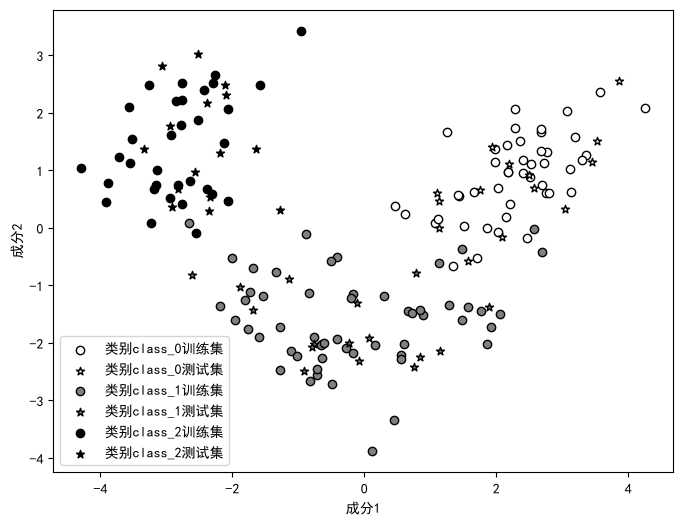

In [7]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']    # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False      # 用来正常显示负号
# 绘制wine数据集图形
plt.figure(figsize=(8, 6))
for i, color, name in zip(np.unique(y), ['white','grey','black'], wine.target_names):
    # 绘制降维后的训练集样本图形
    plt.scatter(X_train_pca[y_train==i,0], X_train_pca[y_train==i,1],
                c=color, marker='o', edgecolors='k', label='类别'+name+'训练集')
    # 绘制降维后的测试集样本图形
    plt.scatter(X_test_pca[y_test==i,0], X_test_pca[y_test==i,1],
                c=color, marker='*', edgecolors='k', label='类别'+name+'测试集')
plt.xlabel("成分1")
plt.ylabel("成分2")
plt.legend(loc='best')
plt.show()


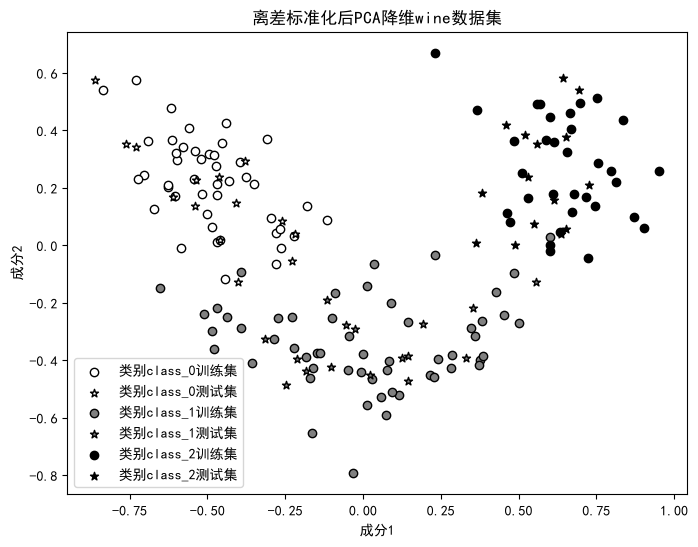

In [8]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
# 离差标准化，只用训练集拟合
mm_scaler = MinMaxScaler()
mm_scaler.fit(X_train)
X_train_minmax = mm_scaler.transform(X_train)
X_test_minmax = mm_scaler.transform(X_test)
# PCA降维到2维
pca_mm = PCA(n_components=2)
pca_mm.fit(X_train_minmax)
X_train_mm_pca = pca_mm.transform(X_train_minmax)
X_test_mm_pca = pca_mm.transform(X_test_minmax)
X_train_mm_pca[:,0] = -X_train_mm_pca[:,0]
X_test_mm_pca[:,0] = -X_test_mm_pca[:,0]
# 绘图（离差标准化版本的图）
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(8,6))
for i, color, name in zip(np.unique(y), ['white','grey','black'], wine.target_names):
    plt.scatter(X_train_mm_pca[y_train==i,0], X_train_mm_pca[y_train==i,1],
                c=color, marker='o', edgecolors='k', label='类别'+name+'训练集')
    plt.scatter(X_test_mm_pca[y_test==i,0], X_test_mm_pca[y_test==i,1],
                c=color, marker='*', edgecolors='k', label='类别'+name+'测试集')
plt.xlabel("成分1")
plt.ylabel("成分2")
plt.legend(loc='best')
plt.title("离差标准化后PCA降维wine数据集")
plt.show()

In [9]:
# ==========二值化处理==========
from sklearn.preprocessing import Binarizer
# 二值化，阈值设置，大于阈值为1，小于等于为0
binarizer = Binarizer(threshold=X_train.mean())
binarizer.fit(X_train)
X_train_bin = binarizer.transform(X_train)
X_test_bin = binarizer.transform(X_test)
print("二值化处理后的数据：")
print(X_train_bin[:3])

二值化处理后的数据：
[[0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 1.]]


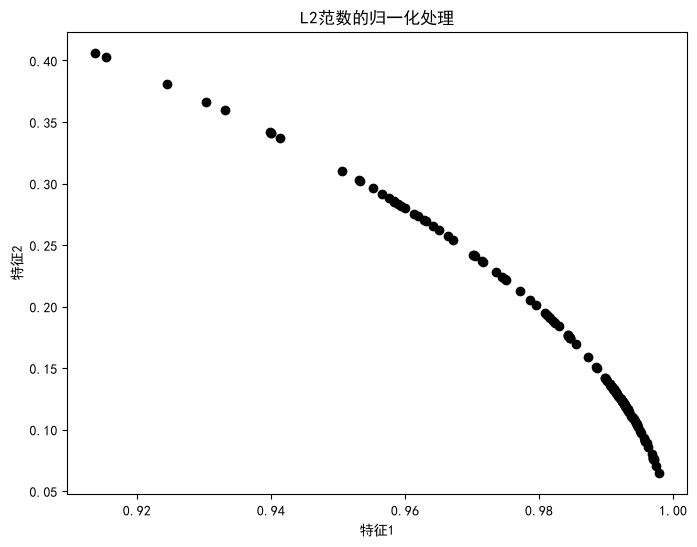

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import Normalizer
X_train_2f = X_train[:, 0:2]
X_test_2f = X_test[:, 0:2]
# L2归一化
norm = Normalizer(norm='l2')
norm.fit(X_train_2f)
X_train_2f_l2 = norm.transform(X_train_2f)
# 绘图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.figure(figsize=(8,6))
plt.scatter(X_train_2f_l2[:,0], X_train_2f_l2[:,1], c="black")
plt.xlabel("特征1")
plt.ylabel("特征2")
plt.title("L2范数的归一化处理")
plt.show()


In [11]:
import numpy as np
from sklearn.preprocessing import OneHotEncoder
data = np.array([[0],
                 [1],
                 [2],
                 [3]])
enc = OneHotEncoder(sparse_output=False)
enc.fit(data)
res = enc.transform(data)
print("编码后的数据：")
print(res)

编码后的数据：
[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
